# Employee Turnover Analytics
Portobello Tech HR data (`HR_comma_sep.csv`): quality checks, EDA, clustering of leavers, SMOTE, 5-fold CV model training, model selection and retention strategies.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score, ConfusionMatrixDisplay, precision_recall_fscore_support, accuracy_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
%matplotlib inline
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
os.makedirs("figs", exist_ok=True); R = {}
def savefig(name):
    plt.tight_layout(); plt.savefig(f"figs/{name}.png", dpi=100, bbox_inches="tight"); plt.show()

## Step 1: Data quality checks

In [2]:
df = pd.read_csv("data/HR_comma_sep.csv")
print(df.shape); display(df.head()); df.info()
print("\nMissing values per column:"); print(df.isna().sum().to_dict())
print("Duplicated rows:", df.duplicated().sum())
print("Target balance:"); print(df["left"].value_counts(normalize=True).round(3).to_dict())
display(df.describe().T.round(3))

(14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB

Missing values per column:
{'satisfaction_level': 0, 'last_evaluation': 0, 'number_project': 0, 'average_montly_hours': 0, 'time_spend_company': 0, 'Work_accident': 0, 'left': 0, 'promotion_last_5years': 0, 'sales': 0, 

,count,mean,std,min,25%,50%,75%,max
satisfaction_level,14999.0,0.613,0.249,0.09,0.44,0.64,0.82,1.0
last_evaluation,14999.0,0.716,0.171,0.36,0.56,0.72,0.87,1.0
number_project,14999.0,3.803,1.233,2.00,3.00,4.00,5.00,7.0
average_montly_hours,14999.0,201.050,49.943,96.00,156.00,200.00,245.00,310.0
time_spend_company,14999.0,3.498,1.460,2.00,3.00,3.00,4.00,10.0
Work_accident,14999.0,0.145,0.352,0.00,0.00,0.00,0.00,1.0
left,14999.0,0.238,0.426,0.00,0.00,0.00,0.00,1.0
promotion_last_5years,14999.0,0.021,0.144,0.00,0.00,0.00,0.00,1.0


In [3]:
# The statement calls the department column "Department"; in the file it is named "sales" (and has a typo'd hours column name).
df = df.rename(columns={"sales":"Department"})
print(df.Department.unique(), df.salary.unique())
R["rows"]=len(df); R["n_dup"]=int(df.duplicated().sum()); R["left_rate"]=float(df.left.mean())

<StringArray>
[      'sales',  'accounting',          'hr',   'technical',     'support',
  'management',          'IT', 'product_mng',   'marketing',       'RandD']
Length: 10, dtype: str <StringArray>
['low', 'medium', 'high']
Length: 3, dtype: str


**Result:** there are no missing values and the dtypes are as expected. The file's department column is named `sales` and is renamed to `Department` to match the problem statement. About 3,000 rows are exact duplicates; since the dataset is a modified Kaggle sample where identical records can be genuine different employees with the same ratings, they are kept (as the brief does not ask to drop them). About 24% of employees left, so the target is imbalanced.

## Step 2: Factors that contributed most to turnover (EDA)

### 2a. Heatmap of the correlation matrix of numerical features

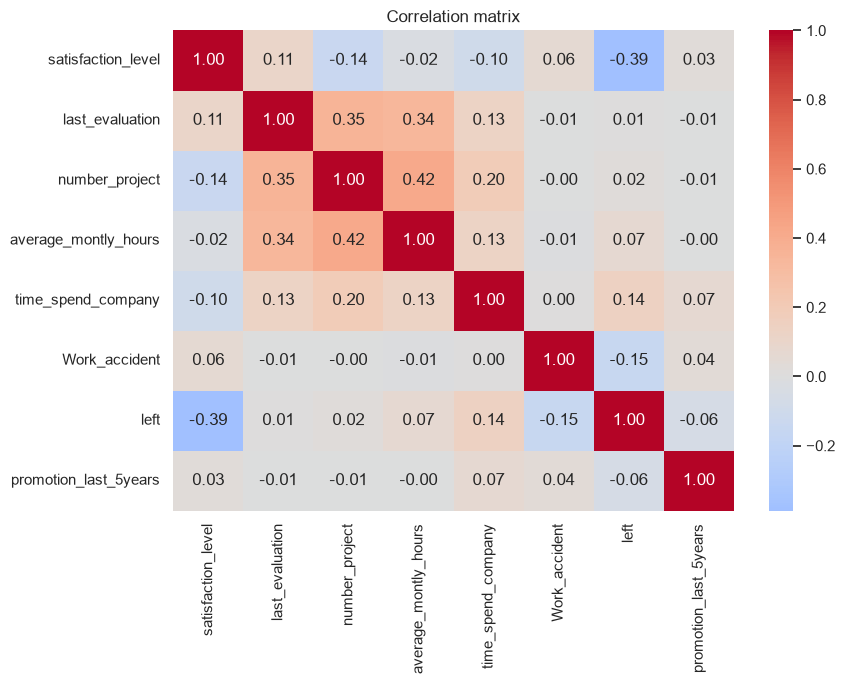

satisfaction_level      -0.388
Work_accident           -0.155
promotion_last_5years   -0.062
last_evaluation          0.007
number_project           0.024
average_montly_hours     0.071
time_spend_company       0.145
Name: left, dtype: float64


In [4]:
num_cols = df.select_dtypes("number").columns.tolist()
plt.figure(figsize=(9,7)); sns.heatmap(df[num_cols].corr(),annot=True,fmt=".2f",cmap="coolwarm",center=0); plt.title("Correlation matrix"); savefig("01_corr_heatmap")
print(df[num_cols].corr()["left"].drop("left").sort_values().round(3))

`satisfaction_level` has by far the strongest (negative) correlation with `left`; `time_spend_company` and `Work_accident` follow, and `promotion_last_5years` is weakly negative. Among features, `number_project`, `last_evaluation` and `average_montly_hours` correlate positively with each other.

### 2b. Distribution plots

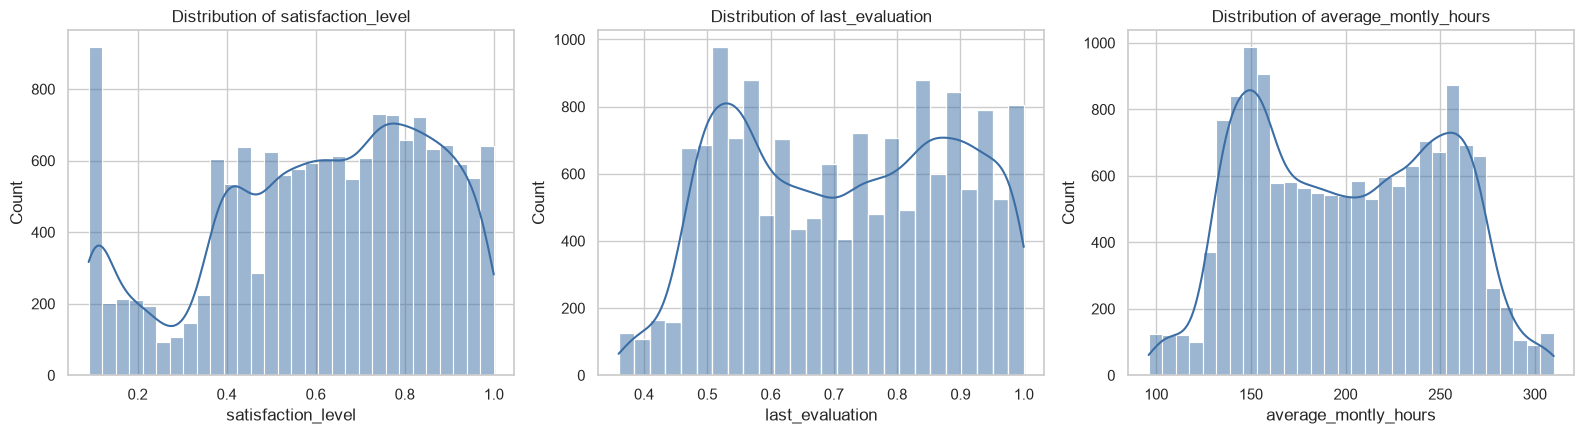

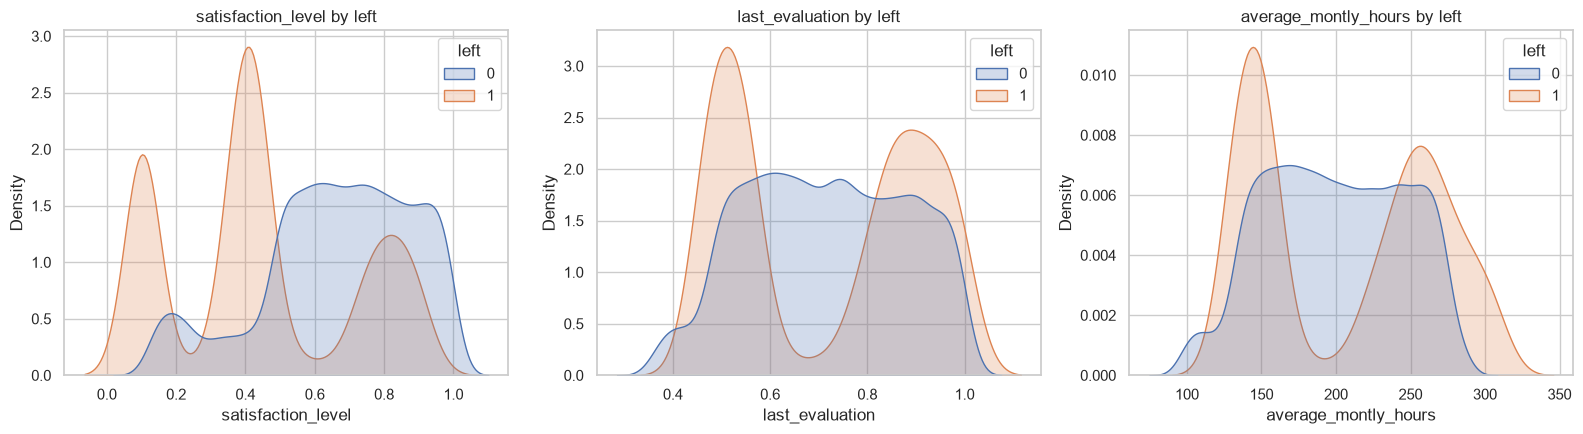

In [5]:
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
for a,c in zip(ax,["satisfaction_level","last_evaluation","average_montly_hours"]):
    sns.histplot(df[c],kde=True,ax=a,color="#3b6ea5"); a.set_title(f"Distribution of {c}")
savefig("02_distributions")
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
for a,c in zip(ax,["satisfaction_level","last_evaluation","average_montly_hours"]):
    sns.kdeplot(data=df,x=c,hue="left",fill=True,common_norm=False,ax=a); a.set_title(f"{c} by left")
savefig("03_distributions_by_left")

Satisfaction is left-skewed with a pronounced low-satisfaction group; last evaluation and monthly hours are bimodal. The split by `left` shows leavers cluster at very low satisfaction, at very high evaluation with heavy hours (overworked high performers) and at moderate satisfaction with mid evaluation.

### 2c. Employee project count for those who left vs. stayed

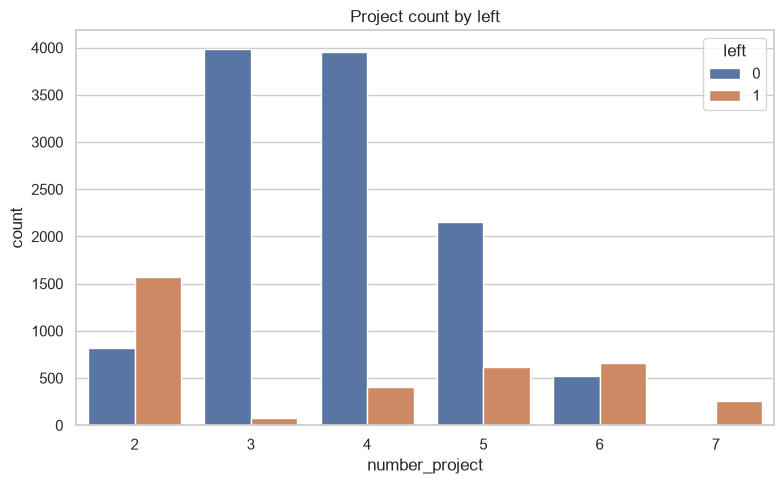

left                0      1
number_project              
2               0.344  0.656
3               0.982  0.018
4               0.906  0.094
5               0.778  0.222
6               0.442  0.558
7               0.000  1.000
left               0     1
number_project            
2                821  1567
3               3983    72
4               3956   409
5               2149   612
6                519   655
7                  0   256


In [6]:
plt.figure(figsize=(8,5)); sns.countplot(data=df,x="number_project",hue="left"); plt.title("Project count by left"); savefig("04_project_count")
print(pd.crosstab(df.number_project,df.left,normalize="index").round(3))
print(pd.crosstab(df.number_project,df.left))

**Inference:** employees with only 2 projects leave at a high rate (under-utilised or underperforming), while those with 6 and 7 projects leave almost always (overwork). Employees with 3 to 5 projects have the lowest attrition, so a moderate workload is the sweet spot.

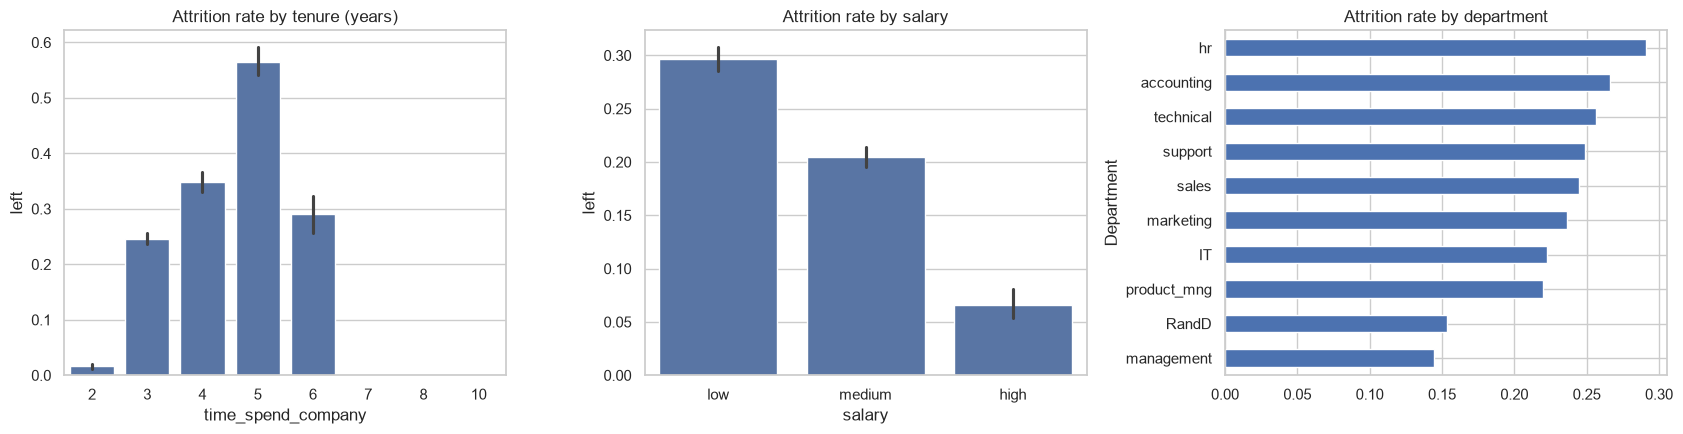

In [7]:
fig,ax=plt.subplots(1,3,figsize=(17,4.5))
sns.barplot(data=df,x="time_spend_company",y="left",ax=ax[0]); ax[0].set_title("Attrition rate by tenure (years)")
sns.barplot(data=df,x="salary",y="left",order=["low","medium","high"],ax=ax[1]); ax[1].set_title("Attrition rate by salary")
dep=df.groupby("Department").left.mean().sort_values(); dep.plot.barh(ax=ax[2]); ax[2].set_title("Attrition rate by department")
savefig("05_other_factors")

Attrition peaks at 4 to 5 years of tenure (35% and 57%), is nil beyond 6 years, falls with higher salary (30% low, 20% medium, 7% high) and varies across departments (HR 29%, accounting 27% and technical 26% highest; management 14% and R&D 15% lowest).

## Step 3: Clustering of employees who left

Cluster sizes: {0: 944, 1: 1650, 2: 977}


satisfaction_level             last_evaluation            
                      mean   min   max            mean   min   max
cluster                                                           
0                     0.11  0.09  0.42            0.87  0.61  1.00
1                     0.41  0.10  0.78            0.52  0.45  0.86
2                     0.81  0.48  0.92            0.91  0.48  1.00

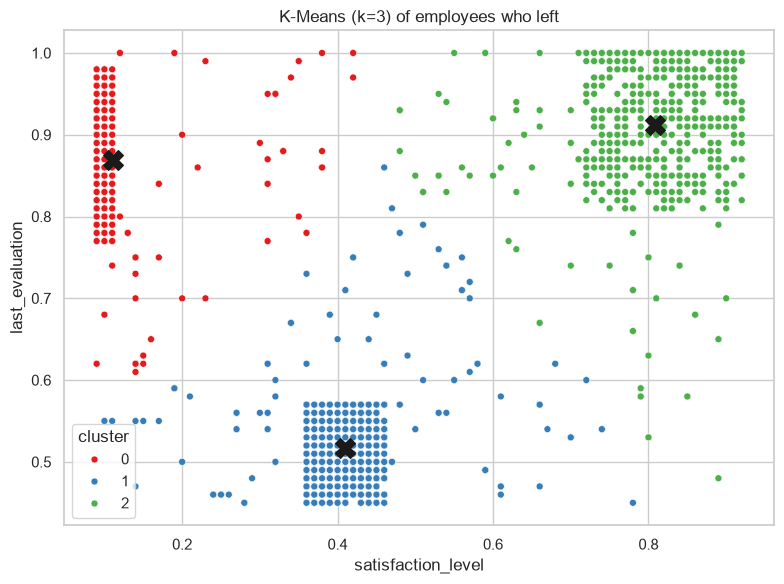

In [8]:
sub = df.loc[df.left==1,["satisfaction_level","last_evaluation"]].copy()
Xc = sub.values
km = KMeans(n_clusters=3,n_init=20,random_state=123).fit(Xc)
sub["cluster"]=km.labels_
print("Cluster sizes:",sub.cluster.value_counts().sort_index().to_dict()); display(sub.groupby("cluster").agg(["mean","min","max"]).round(2))
plt.figure(figsize=(8,6)); sns.scatterplot(data=sub,x="satisfaction_level",y="last_evaluation",hue="cluster",palette="Set1",s=25); plt.scatter(*km.cluster_centers_.T,c="k",marker="X",s=200); plt.title("K-Means (k=3) of employees who left"); savefig("06_leaver_clusters")
R["cluster_summary"]=sub.groupby("cluster").agg(n=("satisfaction_level","size"),sat=("satisfaction_level","mean"),ev=("last_evaluation","mean")).round(3).reset_index().to_dict("records")

**Thoughts on the clusters** (see the means above): the three groups are typically (i) *unhappy and under-evaluated*, low satisfaction and low-to-mid evaluation, i.e. disengaged or poorly matched staff; (ii) *overworked high performers*, very low satisfaction but high evaluation, who are the costliest losses; (iii) *satisfied high performers*, high satisfaction and high evaluation who left anyway, likely for better external offers or career growth. Each type needs a different retention response. K-Means uses only the two columns with k=3 as asked and no scaling is needed since both are on a 0 to 1 scale.

## Step 4: Class imbalance with SMOTE

### 4a. Pre-processing: separate categorical and numeric, `get_dummies`, combine

In [9]:
cat_cols = df.select_dtypes("object").columns.tolist(); print("Categorical:",cat_cols)
cat = df[cat_cols]; numc = df.drop(columns=cat_cols)
cat_d = pd.get_dummies(cat,drop_first=False)
data = pd.concat([numc,cat_d],axis=1).astype({c:int for c in cat_d.columns})
print(data.shape); display(data.head(3))

Categorical: ['Department', 'salary']
(14999, 21)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department_IT,Department_RandD,...,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1


### 4b. Stratified 80:20 split (random_state=123) and SMOTE on the training set

Train/test: (11999, 20) (3000, 20)
Train class counts before SMOTE: {0: 9142, 1: 2857}


Train class counts after SMOTE: {0: 9142, 1: 9142}
Test class counts (untouched): {0: 2286, 1: 714}


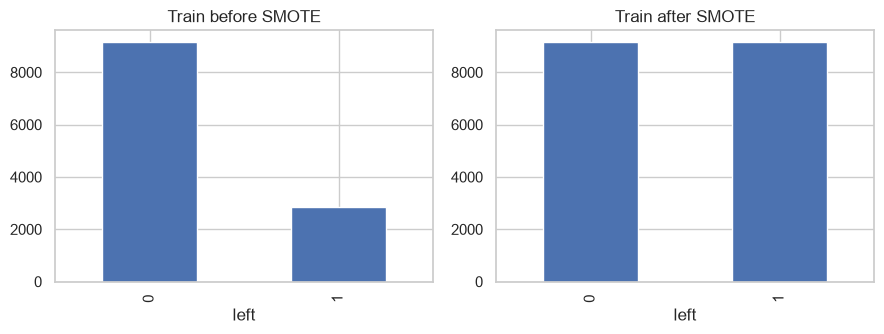

In [10]:
X = data.drop(columns="left"); y = data["left"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.2,stratify=y,random_state=123)
print("Train/test:",X_train.shape,X_test.shape); print("Train class counts before SMOTE:",y_train.value_counts().to_dict())
sm = SMOTE(random_state=123); X_res,y_res = sm.fit_resample(X_train,y_train)
print("Train class counts after SMOTE:",y_res.value_counts().to_dict()); print("Test class counts (untouched):",y_test.value_counts().to_dict())
R["train_before"]=y_train.value_counts().to_dict(); R["train_after"]=y_res.value_counts().to_dict()
fig,ax=plt.subplots(1,2,figsize=(9,3.5)); y_train.value_counts().plot.bar(ax=ax[0],title="Train before SMOTE"); y_res.value_counts().plot.bar(ax=ax[1],title="Train after SMOTE"); savefig("07_smote")

SMOTE is applied only to the training split; the test set stays untouched so that the evaluation reflects the real (imbalanced) population.

## Step 5: 5-fold cross-validation model training and evaluation

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.8065,0.8020,0.8140,0.8079,0.8821
Random Forest,0.9840,0.9932,0.9747,0.9839,0.9977
Gradient Boosting,0.9599,0.9756,0.9433,0.9592,0.9921


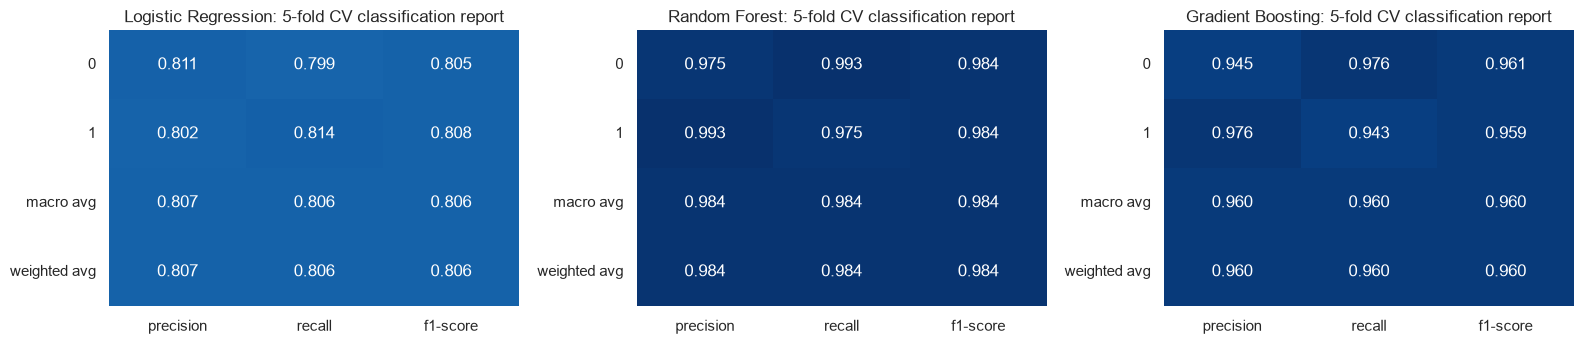

In [11]:
models = {
 "Logistic Regression": make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=123)),
 "Random Forest": RandomForestClassifier(n_estimators=200,random_state=123,n_jobs=-1),
 "Gradient Boosting": GradientBoostingClassifier(random_state=123)}
skf = StratifiedKFold(5,shuffle=True,random_state=123)
def plot_report(rep,title,ax):
    d=pd.DataFrame(rep).T.loc[["0","1","macro avg","weighted avg"],["precision","recall","f1-score"]]
    sns.heatmap(d,annot=True,fmt=".3f",cmap="Blues",vmin=0,vmax=1,ax=ax,cbar=False); ax.set_title(title)
cv_rows=[]; reports_cv={}
for nm,m in models.items():
    cvr = cross_validate(m,X_res,y_res,cv=skf,scoring=["accuracy","precision","recall","f1","roc_auc"],n_jobs=1)
    cv_rows.append({"model":nm,**{k.replace("test_",""):v.mean() for k,v in cvr.items() if k.startswith("test_")}})
    pred = cross_val_predict(m,X_res,y_res,cv=skf); reports_cv[nm]=classification_report(y_res,pred,output_dict=True)
cv_df=pd.DataFrame(cv_rows).set_index("model").round(4); display(cv_df); R["cv"]=cv_df.reset_index().to_dict("records")
fig,ax=plt.subplots(1,3,figsize=(16,3.6))
for a,nm in zip(ax,models): plot_report(reports_cv[nm],f"{nm}: 5-fold CV classification report",a)
savefig("08_cv_classification_reports")

These 5-fold CV scores are computed on the SMOTE-upsampled training data, as the brief prescribes. Because synthetic points in a validation fold are interpolated from neighbours that sit in the training folds, this CV is somewhat optimistic. The next cell therefore repeats CV with SMOTE applied inside each fold (leak-free), and the held-out test set below is the honest benchmark.

In [12]:
leak_rows=[]
for nm,m in models.items():
    pipe = ImbPipeline([("smote",SMOTE(random_state=123)),("clf",m)])
    cvr = cross_validate(pipe,X_train,y_train,cv=skf,scoring=["accuracy","precision","recall","f1","roc_auc"])
    leak_rows.append({"model":nm,**{k.replace("test_",""):v.mean() for k,v in cvr.items() if k.startswith("test_")}})
leak_df=pd.DataFrame(leak_rows).set_index("model").round(4); display(leak_df); R["cv_leakfree"]=leak_df.reset_index().to_dict("records")

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.7816,0.5324,0.6885,0.6003,0.8215
Random Forest,0.9857,0.9800,0.9594,0.9696,0.9921
Gradient Boosting,0.9677,0.9298,0.9352,0.9325,0.9883


### Test-set classification reports

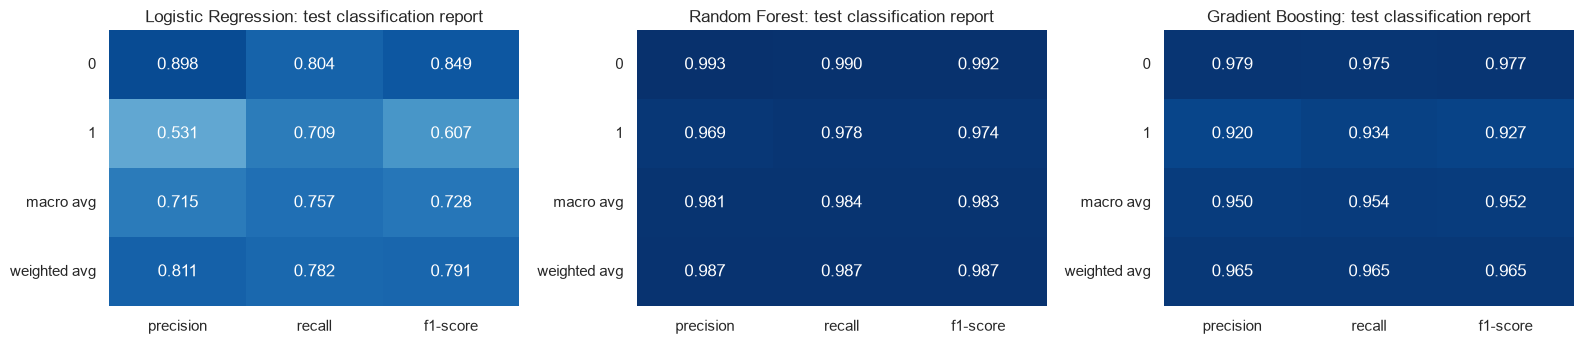

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.7817,0.5310,0.7087,0.6071,0.8203
Random Forest,0.9873,0.9694,0.9776,0.9735,0.9951
Gradient Boosting,0.9650,0.9200,0.9342,0.9270,0.9857


In [13]:
fitted={}; probs={}; test_rows=[]; fig,ax=plt.subplots(1,3,figsize=(16,3.6))
for a,(nm,m) in zip(ax,models.items()):
    m.fit(X_res,y_res); fitted[nm]=m; pr=m.predict_proba(X_test)[:,1]; probs[nm]=pr; pred=(pr>=.5).astype(int)
    rep=classification_report(y_test,pred,output_dict=True); plot_report(rep,f"{nm}: test classification report",a)
    p,r,f,_=precision_recall_fscore_support(y_test,pred,average="binary")
    test_rows.append({"model":nm,"accuracy":accuracy_score(y_test,pred),"precision":p,"recall":r,"f1":f,"roc_auc":roc_auc_score(y_test,pr)})
savefig("09_test_classification_reports")
test_df=pd.DataFrame(test_rows).set_index("model").round(4); display(test_df); R["test"]=test_df.reset_index().to_dict("records")

## Step 6: Best model and justification of metrics

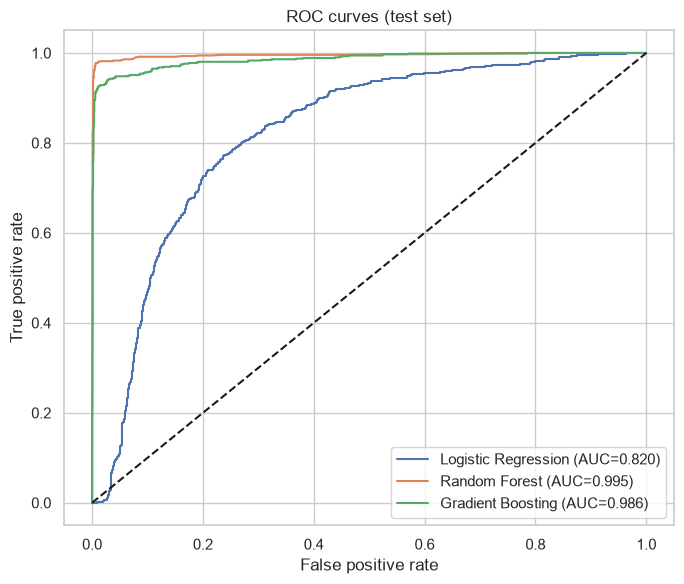

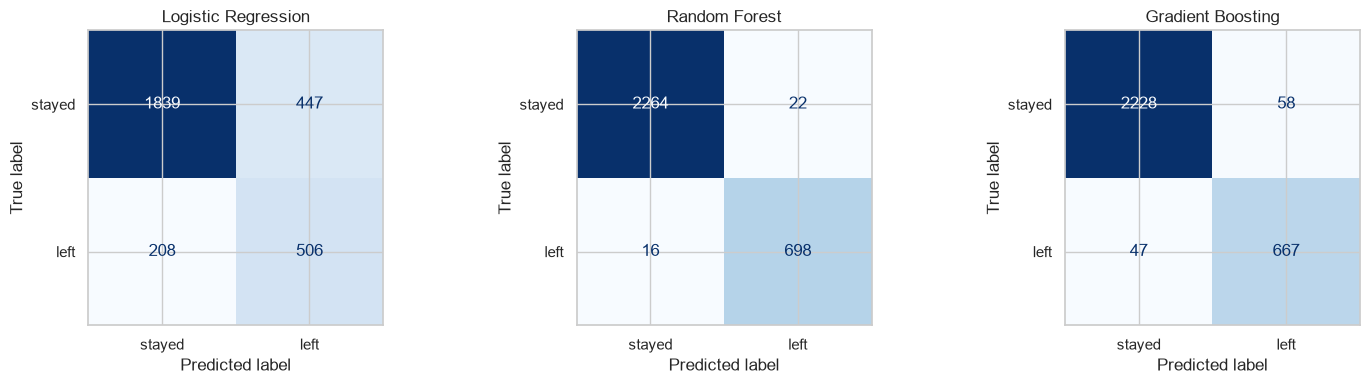

{'Logistic Regression': [[1839, 447], [208, 506]], 'Random Forest': [[2264, 22], [16, 698]], 'Gradient Boosting': [[2228, 58], [47, 667]]}


In [14]:
plt.figure(figsize=(7,6))
for nm,pr in probs.items():
    fpr,tpr,_=roc_curve(y_test,pr); plt.plot(fpr,tpr,label=f"{nm} (AUC={roc_auc_score(y_test,pr):.3f})")
plt.plot([0,1],[0,1],"k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (test set)"); plt.legend(); savefig("10_roc")
fig,ax=plt.subplots(1,3,figsize=(15,4)); cms={}
for a,(nm,pr) in zip(ax,probs.items()):
    cm=confusion_matrix(y_test,(pr>=.5).astype(int)); cms[nm]=cm.tolist(); ConfusionMatrixDisplay(cm,display_labels=["stayed","left"]).plot(ax=a,colorbar=False,cmap="Blues"); a.set_title(nm)
savefig("11_confusion_matrices"); R["confusion"]=cms; print(cms)

In [15]:
best = test_df.sort_values(["roc_auc","recall"],ascending=False).index[0]; print("Best model:",best); R["best"]=best
print(test_df.sort_values("roc_auc",ascending=False))

Best model: Random Forest
                     accuracy  precision  recall      f1  roc_auc
model                                                            
Random Forest          0.9873     0.9694  0.9776  0.9735   0.9951
Gradient Boosting      0.9650     0.9200  0.9342  0.9270   0.9857
Logistic Regression    0.7817     0.5310  0.7087  0.6071   0.8203


**Metric choice: Recall versus Precision.** In the confusion matrix, a false negative means an employee who will leave is missed (lost knowledge, replacement cost, no chance to intervene), while a false positive only triggers a retention conversation or incentive for someone who would have stayed, which is comparatively cheap. Therefore **recall of the 'left' class is the primary metric**, while precision is monitored so that the retention budget is not wasted, and the F1 score and ROC-AUC summarise the balance and the ranking quality independent of threshold. Accuracy alone is misleading with 24% leavers. The best model is the one with the highest ROC-AUC on the test set with strong recall (see table above).

## Step 7: Retention strategies by risk zone

,employees,mean_prob,actual_leave_rate,satisfaction,projects,hours,tenure
zone,,,,,,,
Safe (Green) <20%,2165,0.031,0.005,0.678,3.758,198.212,3.336
Low-Risk (Yellow) 20-60%,126,0.325,0.071,0.464,3.952,218.770,4.024
Medium-Risk (Orange) 60-90%,63,0.772,0.841,0.582,4.460,225.683,4.349
High-Risk (Red) >90%,646,0.992,0.994,0.426,3.851,208.443,3.870


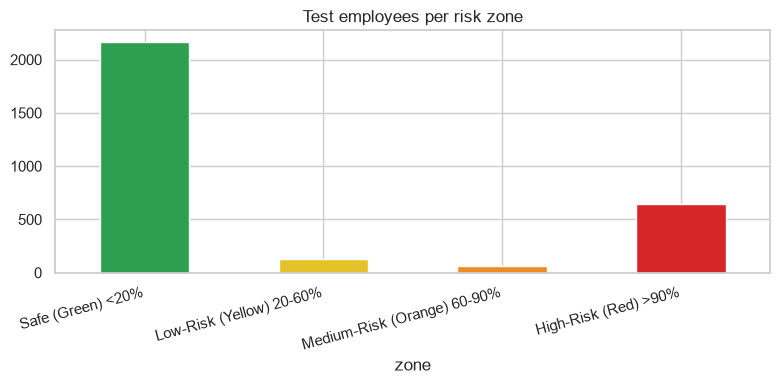

In [16]:
best_model=fitted[best]; p=best_model.predict_proba(X_test)[:,1]
zone=pd.cut(p,[-0.001,.2,.6,.9,1.001],labels=["Safe (Green) <20%","Low-Risk (Yellow) 20-60%","Medium-Risk (Orange) 60-90%","High-Risk (Red) >90%"])
res=X_test.copy(); res["p_leave"]=p; res["zone"]=zone; res["left_actual"]=y_test.values
zs=res.groupby("zone").agg(employees=("p_leave","size"),mean_prob=("p_leave","mean"),actual_leave_rate=("left_actual","mean"),satisfaction=("satisfaction_level","mean"),projects=("number_project","mean"),hours=("average_montly_hours","mean"),tenure=("time_spend_company","mean")).round(3)
display(zs); R["zones"]=zs.reset_index().astype({"zone":str}).to_dict("records")
plt.figure(figsize=(8,4)); colors=["#2e9e4f","#e6c229","#f08a24","#d62728"]; zs.employees.plot.bar(color=colors); plt.title("Test employees per risk zone"); plt.xticks(rotation=15,ha="right"); savefig("12_risk_zones")

**Retention strategies per zone** (the table shows each zone's actual leave rate and average profile, which should rise from Green to Red):

- **Safe (Green, <20%)**: employees are stable. Keep them that way with routine engagement: recognition, fair compensation reviews, annual career conversations and pulse surveys. Use them as mentors and as a reference group for what works.
- **Low-Risk (Yellow, 20-60%)**: early-warning group. Run manager check-ins, monitor workload (project count and hours) and satisfaction trends, offer training and a clear growth path, and fix small issues such as stalled promotions before they escalate.
- **Medium-Risk (Orange, 60-90%)**: act proactively. Hold stay interviews, rebalance workload (avoid 6+ projects or very long hours), review salary and promotion eligibility (especially for staff with 3 to 5 years of tenure and no promotion), and offer flexibility, new challenges or a role change.
- **High-Risk (Red, >90%)**: immediate, personalised intervention led by senior management and HR: retention bonus or counter-offer, promotion or a clearly defined role upgrade for high performers, workload relief for the overworked, and a transparent plan; for low performers who are disengaged, consider redeployment or a supportive transition. Prioritise by evaluation score so the best performers are retained first.

Overall levers supported by the EDA: keep project loads at 3 to 5, address the 4 to 5 year tenure cliff, link promotions and pay to performance, and monitor satisfaction continuously since it is the strongest predictor.

## Conclusions
- No missing values; ~24% attrition (imbalanced), balanced by SMOTE on the training split only.
- Satisfaction, project count, tenure and hours are the key turnover drivers.
- Leavers form three clusters by satisfaction and evaluation, each needing a different retention approach.
- Tree ensembles clearly outperform logistic regression; the best model is chosen on test ROC-AUC and recall.
- Risk zones convert predictions into actionable retention plans.

In [17]:
json.dump(R,open("results.json","w"),indent=1,default=str); print("saved")

saved
